# 9장. 회귀 분석으로 숫자 예측하기

이 Notebook의 핵심은 높은 점수를 만드는 것이 아니라 다음 순서를 지키는 것입니다.

`예측 시점 → 누수 방지 → 시간 분할 → Train TimeSeriesSplit → 모델 선택 고정 → Final Test → Baseline 비교`

**Final Test 결과를 보고 모델을 고르지 않습니다.**

## 0. 실행 전 확인

Chapter09는 Chapter05의 오류 탐지용 전용 Raw가 아니라 **공통 프로젝트 `data/raw`**를 사용합니다. 먼저 프로젝트 루트에서 다음 명령을 실행해 관계 검증을 통과한 모델링 입력을 준비합니다.

```powershell
python scripts/prepare_ch09_data.py
```

이 명령은 공통 `data/raw`를 전처리하고 FK 관계를 검증한 뒤 `data/processed/*_clean.csv`를 생성합니다.

In [1]:
from pathlib import Path
import sys
import pandas as pd


def find_project_root(start=Path.cwd().resolve()):
    for path in (start, *start.parents):
        if (path / "data" / "raw").is_dir() and (path / "src").is_dir():
            return path
    raise FileNotFoundError("프로젝트 루트를 찾지 못했습니다.")


PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports"

from src.regression import (
    FEATURE_COLUMNS,
    FORBIDDEN_FEATURES,
    TARGET_COLUMN,
    build_feature_audit,
    build_leakage_checklist,
    build_regression_dataset,
    build_regression_validation,
    build_split_summary,
    create_prediction_result,
    cross_validate_regression_models,
    load_regression_source_data,
    make_one_hot_encoder,
    make_regression_models,
    run_regression_analysis,
    save_regression_outputs,
    select_diagnostic_model,
    split_model_data_by_time,
    train_and_evaluate_models,
    validate_feature_columns,
)

print("저장소 루트:", PROJECT_ROOT.name)
print("모델링 입력:", PROCESSED_DIR.relative_to(PROJECT_ROOT))

저장소 루트: llm-data-analysis-study
모델링 입력: data/processed


## 1. 예측 문제와 예측 시점

- Target: 주문 1건의 주문 상세 금액 합계 `order_total`
- 예측 시점: 주문 메타데이터와 고객의 비식별 특성은 알 수 있지만 주문 상세 수량·단가·금액은 모델에 제공하지 않는 시점
- 목표 계산 재료와 사후 정보, 식별자는 feature에서 제외합니다.

In [2]:
print('Target:', TARGET_COLUMN)
print('Allowed features:', FEATURE_COLUMNS)
print('Forbidden features:', sorted(FORBIDDEN_FEATURES))
validate_feature_columns()
print('Feature leakage gate: PASS')

Target: order_total
Allowed features: ['order_month', 'order_dayofweek', 'age', 'payment_method', 'gender', 'city']
Forbidden features: ['avg_unit_price', 'customer_id', 'item_count', 'line_total', 'order_id', 'order_status', 'order_total', 'product_id', 'quantity', 'total_quantity', 'unit_price']
Feature leakage gate: PASS


## 2. 검증된 전처리 데이터를 불러옵니다

In [3]:
data = load_regression_source_data(PROCESSED_DIR)
for name, frame in data.items():
    print(name, frame.shape)

customers (150, 6)
orders (300, 7)
order_items (764, 6)


## 3. 주문 단위 Target을 만들고 관계를 검증합니다

`line_total = quantity × unit_price`를 확인하고, 주문과 Target은 `one_to_one`, 주문과 고객은 `many_to_one` 관계가 깨지지 않는지 확인합니다.

In [4]:
model_data = build_regression_dataset(
    customers=data['customers'],
    orders=data['orders'],
    order_items=data['order_items'],
)
display(model_data.head())
print('Model rows:', len(model_data))

,order_id,customer_id,order_date,payment_method,order_status,order_month,order_dayofweek,order_total,gender,age,city
0,238,124,2025-07-09,bank_transfer,completed,7,2,361000,M,67,대구
1,79,62,2025-07-11,bank_transfer,refunded,7,4,283000,F,63,광주
2,12,98,2025-07-12,kakao_pay,completed,7,5,444000,F,61,인천
3,169,9,2025-07-12,kakao_pay,completed,7,5,448000,M,69,서울
4,152,62,2025-07-13,naver_pay,refunded,7,6,985000,F,63,광주


Model rows: 300


## 4. Feature Audit을 확인합니다

In [5]:
feature_audit = build_feature_audit()
display(feature_audit)

,column,selected,role,reason
0,order_month,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
1,order_dayofweek,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
2,age,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
3,payment_method,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
4,gender,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
5,city,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
6,avg_unit_price,False,forbidden,주문 상세에서 만든 목표 대리 변수
7,customer_id,False,forbidden,고객 식별자
8,item_count,False,forbidden,주문 상세가 확인된 뒤 계산되는 사후 집계
9,line_total,False,forbidden,목표값을 구성하는 주문 상세 금액


## 5. 시간 순서로 Train / Final Test를 분리합니다

같은 달력 날짜를 양쪽에 나누지 않습니다. Final Test는 모델 선택이 끝날 때까지 사용하지 않습니다.

In [6]:
train_data, test_data = split_model_data_by_time(model_data, test_size=0.2)
split_summary = build_split_summary(train_data, test_data)
display(split_summary)
assert train_data['order_date'].max().normalize() < test_data['order_date'].min().normalize()
print('Chronological split gate: PASS')

,split,rows,ratio_pct,start_date,end_date
0,train,244,81.33,2025-07-09,2026-04-13
1,test,56,18.67,2026-04-14,2026-07-08


Chronological split gate: PASS


In [7]:
X_train = train_data[FEATURE_COLUMNS].copy()
X_test = test_data[FEATURE_COLUMNS].copy()
y_train = train_data[TARGET_COLUMN].copy()
y_test = test_data[TARGET_COLUMN].copy()
print('Train:', X_train.shape, 'Final Test:', X_test.shape)

Train: (244, 6) Final Test: (56, 6)


## 6. Pipeline 후보 모델을 준비합니다

숫자형 결측 대체·표준화와 범주형 결측 대체·One-Hot Encoding은 모델 Pipeline 안에서 각 Train Fold로만 학습됩니다.

In [8]:
models = make_regression_models(random_state=42)
print(list(models))

['Baseline Mean', 'Linear Regression', 'Random Forest']


## 7. Train 기간의 TimeSeriesSplit으로 후보를 비교합니다

여기까지는 Final Test의 `y_test`를 모델 선택에 사용하지 않습니다.

In [9]:
cv_summary = cross_validate_regression_models(
    models=models,
    X_train=X_train,
    y_train=y_train,
)
display(cv_summary)

,model,n_splits,cv_MAE_mean,cv_MAE_std,cv_R2_mean
0,Baseline Mean,5,423004.808743,44153.043466,-0.022821
1,Random Forest,5,437352.803929,26318.793429,-0.109687
2,Linear Regression,5,461386.286905,77792.799324,-0.310517


## 8. 비베이스라인 모델 선택을 고정합니다

Linear Regression과 Random Forest 중 Train CV의 평균 MAE가 더 낮은 모델을 선택합니다. **이 시점까지 Final Test 성능은 보지 않습니다.**

In [10]:
selected_model_name = select_diagnostic_model(cv_summary)
print('Frozen selected model:', selected_model_name)

Frozen selected model: Random Forest


## 9. 이제 Final Test에서 Baseline과 고정 모델만 평가합니다

Final Test 결과가 기대와 다르더라도 같은 Test를 보고 다른 후보로 교체하지 않습니다.

In [11]:
model_comparison, predictions = train_and_evaluate_models(
    models=models,
    selected_model_name=selected_model_name,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test,
)
display(model_comparison)

,model,selection_role,train_MAE,test_MAE,test_RMSE,test_R2,MAE_improvement_vs_baseline_pct
0,Baseline Mean,baseline,416266.191884,443449.648712,522189.699620,-0.001121,0.00
1,Random Forest,selected_by_train_cv,326438.478132,458819.917234,548190.446723,-0.103298,-3.47


### 지표 읽기

- MAE: 평균적으로 얼마만큼 틀리는가
- RMSE: 큰 오차에 더 민감
- R²: 평균 예측 대비 설명력, 음수가 될 수 있음
- MAE 개선율: Dummy baseline 대비 고정 모델의 Final Test MAE 개선 정도

## 10. 실제값·예측값·잔차를 진단합니다

In [12]:
prediction_result = create_prediction_result(
    test_data=test_data,
    y_test=y_test,
    y_pred=predictions[selected_model_name],
    model_name=selected_model_name,
)
display(prediction_result.drop(columns=['order_id']).head(10))
print('공개 Notebook에서는 내부 order_id를 제외했습니다.')

,order_date,actual_order_total,predicted_order_total,residual,abs_error,model
0,2026-06-15,1877000,605528.715709,1.271471e+06,1.271471e+06,Random Forest
1,2026-06-19,1767000,756889.654706,1.010110e+06,1.010110e+06,Random Forest
2,2026-05-27,1863000,861784.708271,1.001215e+06,1.001215e+06,Random Forest
3,2026-05-11,1690000,694946.179725,9.950538e+05,9.950538e+05,Random Forest
4,2026-05-23,1685000,745836.316118,9.391637e+05,9.391637e+05,Random Forest
5,2026-06-11,10000,897415.394314,-8.874154e+05,8.874154e+05,Random Forest
6,2026-05-23,1677000,849179.542426,8.278205e+05,8.278205e+05,Random Forest
7,2026-07-08,86000,904745.854532,-8.187459e+05,8.187459e+05,Random Forest
8,2026-04-24,1566000,758941.292777,8.070587e+05,8.070587e+05,Random Forest
9,2026-06-14,72000,871636.144070,-7.996361e+05,7.996361e+05,Random Forest


공개 Notebook에서는 내부 order_id를 제외했습니다.


## 11. 자동 Validation Evidence를 만듭니다

In [13]:
validation = build_regression_validation(
    train_data=train_data,
    test_data=test_data,
    cv_summary=cv_summary,
    selected_model_name=selected_model_name,
    model_comparison=model_comparison,
)
display(validation)
assert validation['status'].eq('PASS').all()

,check,value,status
0,forbidden_feature_overlap,0,PASS
1,strict_train_before_test,True,PASS
2,selected_model_exists_in_train_cv,True,PASS
3,final_test_contains_baseline,True,PASS
4,final_test_contains_frozen_selected_model,True,PASS
5,test_rows_for_r2,56,PASS


## 12. Evidence·내부 진단·공개 보고서를 구분해 저장합니다

In [14]:
checklist = build_leakage_checklist()
output_paths = save_regression_outputs(
    model_data=model_data,
    split_summary=split_summary,
    feature_audit=feature_audit,
    cv_summary=cv_summary,
    selected_model_name=selected_model_name,
    model_comparison=model_comparison,
    prediction_result=prediction_result,
    validation=validation,
    checklist=checklist,
    report_dir=REPORT_DIR,
)
for name, path in output_paths.items():
    print(name, '->', path.relative_to(PROJECT_ROOT))

model_data_internal -> reports/ch09_regression_model_data_internal.csv
split_summary -> reports/ch09_regression_split_summary.csv
feature_audit -> reports/ch09_regression_feature_audit.csv
cv_summary -> reports/ch09_regression_cv_summary.csv
model_comparison -> reports/ch09_regression_model_comparison.csv
predictions_internal -> reports/ch09_regression_predictions_internal.csv
validation -> reports/ch09_regression_validation.csv
checklist -> reports/ch09_regression_checklist.csv
report -> reports/ch09_regression_report.md
actual_vs_predicted_figure -> reports/figures/ch09_actual_vs_predicted.png
residual_figure -> reports/figures/ch09_residual_histogram.png


## 13. 전체 공통 함수를 새 실행으로 다시 확인합니다

셀의 메모리 상태가 아니라 공통 함수가 같은 순서를 재현하는지 확인합니다.

In [15]:
result = run_regression_analysis(
    processed_dir=PROCESSED_DIR,
    report_dir=REPORT_DIR,
    test_size=0.2,
    random_state=42,
)
print('Selected by Train CV:', result['selected_model_name'])
display(result['validation'])

Selected by Train CV: Random Forest


,check,value,status
0,forbidden_feature_overlap,0,PASS
1,strict_train_before_test,True,PASS
2,selected_model_exists_in_train_cv,True,PASS
3,final_test_contains_baseline,True,PASS
4,final_test_contains_frozen_selected_model,True,PASS
5,test_rows_for_r2,56,PASS


## 14. 해석

낮은 성능이나 음수 R²도 숨기지 않습니다. 현재 예측 시점에 허용한 정보가 약하다면 `현재 데이터로는 모델 사용 보류`도 올바른 결론입니다.

LLM이 만든 코드도 같은 예측 시점·누수·Pipeline·Train CV·Final Test 보호 기준으로 검토합니다.

## 15. 완료 체크

- [x] `python scripts/prepare_ch09_data.py`로 공통 모델링 입력을 준비했다.
- [x] Target과 예측 시점을 설명할 수 있다.
- [x] 금지 feature가 입력에 없음을 확인했다.
- [x] 같은 날짜가 Train과 Final Test에 동시에 들어가지 않는다.
- [x] 전처리는 Pipeline 내부에서 학습된다.
- [x] Train TimeSeriesSplit으로 후보를 비교했다.
- [x] Final Test 전에 Selected Model을 고정했다.
- [x] Final Test에서는 Baseline과 Frozen Model만 비교했다.
- [x] MAE, RMSE, R²를 함께 읽었다.
- [x] 내부 식별자 결과와 공개 보고서를 구분했다.
- [x] Validation Evidence가 모두 PASS다.

# Chapter 09 제출 답안

- **GitHub ID:** `chocoemong1`
- **작성일:** 2026-11-02
- **최종 Notebook URL:** <https://github.com/chocoemong1/llm-data-analysis-study/blob/main/chapter09/chapter09.ipynb>

아래 답안은 위의 실제 실행 결과와 저장된 Evidence를 기준으로 작성했습니다.

In [16]:
import matplotlib.pyplot as plt
from matplotlib import font_manager

IMAGE_DIR = PROJECT_ROOT / "chapter09" / "images"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

font_candidates = [
    Path.home() / "research" / "프로그램 모음" / "tools" / "fonts" / "noto-cjk-20230817" / "NotoSansCJKkr-Regular.otf",
    Path("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"),
]
font_path = next((path for path in font_candidates if path.exists()), None)
if font_path:
    font_manager.fontManager.addfont(font_path)
    plt.rcParams["font.family"] = font_manager.FontProperties(fname=font_path).get_name()
plt.rcParams["axes.unicode_minus"] = False


def save_table_image(frame, path, title, figsize=(12, 4), font_size=9):
    shown = frame.copy()
    for column in shown.columns:
        if pd.api.types.is_float_dtype(shown[column]):
            shown[column] = shown[column].round(2)
    fig, ax = plt.subplots(figsize=figsize)
    ax.axis("off")
    ax.set_title(title, fontsize=14, pad=12)
    table = ax.table(
        cellText=shown.astype(str).values,
        colLabels=shown.columns,
        cellLoc="center",
        loc="center",
    )
    table.auto_set_font_size(False)
    table.set_fontsize(font_size)
    table.scale(1, 1.35)
    fig.tight_layout()
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.close(fig)


save_table_image(
    feature_audit[["column", "selected", "role", "reason"]],
    IMAGE_DIR / "step02_leakage.png",
    "Feature Leakage Audit",
    figsize=(13, 8),
    font_size=8,
)
split_evidence = split_summary.copy()
split_evidence["start_date"] = split_evidence["start_date"].astype(str)
split_evidence["end_date"] = split_evidence["end_date"].astype(str)
save_table_image(
    split_evidence,
    IMAGE_DIR / "step04_split.png",
    "Train / Final Test 시간 분할",
    figsize=(10, 2.6),
)
metric_evidence = model_comparison.rename(
    columns={
        'selection_role': 'role',
        'train_MAE': 'train MAE',
        'test_MAE': 'test MAE',
        'test_RMSE': 'test RMSE',
        'test_R2': 'test R2',
        'MAE_improvement_vs_baseline_pct': 'MAE improvement (%)',
    }
)
save_table_image(
    metric_evidence,
    IMAGE_DIR / "step06_final_metrics.png",
    "Baseline vs Frozen Model",
    figsize=(13, 2.8),
    font_size=8,
)
print("Evidence images:", sorted(path.name for path in IMAGE_DIR.glob("step*.png")))

Evidence images: ['step02_leakage.png', 'step04_split.png', 'step06_final_metrics.png']


In [17]:
items_check = data["order_items"].copy()
calculated_line_total = items_check["quantity"] * items_check["unit_price"]
line_total_mismatches = int((items_check["line_total"] != calculated_line_total).sum())
target_by_order = items_check.groupby("order_id", as_index=False)["line_total"].sum()
target_by_order = target_by_order.rename(columns={"line_total": "order_total"})
orders_target_ok = (
    target_by_order["order_id"].is_unique
    and len(target_by_order) == len(data["orders"])
    and set(target_by_order["order_id"]) == set(data["orders"]["order_id"])
)
invalid_customer_fk = int((~data["orders"]["customer_id"].isin(data["customers"]["customer_id"])).sum())

relationship_evidence = pd.DataFrame(
    [
        ["line_total = quantity × unit_price", line_total_mismatches, "PASS" if line_total_mismatches == 0 else "FAIL"],
        ["orders ↔ target one_to_one", orders_target_ok, "PASS" if orders_target_ok else "FAIL"],
        ["orders → customers many_to_one", invalid_customer_fk, "PASS" if invalid_customer_fk == 0 else "FAIL"],
    ],
    columns=["check", "value", "status"],
)
display(relationship_evidence)
assert relationship_evidence["status"].eq("PASS").all()

,check,value,status
0,line_total = quantity × unit_price,0,PASS
1,orders ↔ target one_to_one,True,PASS
2,orders → customers many_to_one,0,PASS


## 1. 기본 회귀 실습 답안

### 예측 문제·시점

- **Target:** 주문 1건의 `order_total`
- **예측 단위:** 주문 1건
- **예측 시점:** 주문 메타데이터와 고객의 비식별 특성은 알지만 주문 상세는 알 수 없다고 가정한 시점
- **사용 가능:** `order_month`, `order_dayofweek`, `age`, `payment_method`, `gender`, `city`
- **사용 불가:** Target·계산 재료·사후 정보·식별자

**나의 판단:** 실제 예측 시점에 알 수 없는 주문 수량·단가를 입력에 넣지 않아야 성능이 과대평가되지 않습니다.

### Target·관계 검증

- `line_total = quantity × unit_price`, 불일치 0건
- `order_total = order_id`별 `line_total` 합계
- orders ↔ target `one_to_one` PASS
- orders → customers `many_to_one` PASS

관계 검증 없이 병합하면 행 증식·손실이 조용히 발생해 Target과 평가 결과가 왜곡될 수 있습니다.

## 2. Feature Leakage Audit

![Leakage 점검](images/step02_leakage.png)

- **금지 feature overlap:** 0개
- **가장 위험한 feature:** `order_total`, `line_total`, `quantity`, `unit_price`
- **이유:** Target 자체이거나 Target을 정확히 계산하는 재료이므로 누수입니다.
- 숫자형은 median 대체·표준화, 범주형은 최빈값 대체·One-Hot Encoding을 **Pipeline 내부의 Train Fold에서만 fit**했습니다.

## 3. 시간 분할·Train CV·모델 고정

![시간 분할](images/step04_split.png)

- **Train:** 2025-07-09~2026-04-13, 244행
- **Final Test:** 2026-04-14~2026-07-08, 56행
- **같은 날짜 중복:** 없음

미래 주문을 과거 주문으로 예측하는 상황을 모사하기 위해 무작위 분할보다 시간 순서 분할을 사용했습니다.

| 모델 | CV MAE 평균 | CV MAE 표준편차 | CV R² 평균 |
| --- | ---: | ---: | ---: |
| Baseline Mean | 423,005 | 44,153 | -0.023 |
| Linear Regression | 461,386 | 77,793 | -0.311 |
| Random Forest | 437,353 | 26,319 | -0.110 |

- **Selected Model:** Random Forest
- **선택 기준:** 비베이스라인 후보 중 Train CV MAE 평균 최소
- **Final Test를 보기 전 선택:** 예

CV 표준편차는 평균 성능이 시간 Fold에 따라 얼마나 흔들리는지 보여주므로 함께 확인했습니다.

## 4. Final Test·오차·Validation

![최종 회귀 평가](images/step06_final_metrics.png)

| 모델 | role | Train MAE | Test MAE | Test RMSE | Test R² | Baseline 대비 MAE 개선율 |
| --- | --- | ---: | ---: | ---: | ---: | ---: |
| Baseline Mean | baseline | 416,266 | 443,450 | 522,190 | -0.001 | 0.00% |
| Random Forest | selected_by_train_cv | 326,438 | 458,820 | 548,190 | -0.103 | -3.47% |

### 결과 관찰

Frozen Random Forest의 Test MAE는 약 458,820원이고 Baseline보다 3.47% 나쁘며 R²도 음수입니다. RMSE가 MAE보다 크므로 일부 큰 오차의 영향이 있습니다.

### 나의 해석과 판단

현재 feature는 주문금액 변동을 충분히 설명하지 못합니다. Final Test를 보고 다른 후보로 교체하지 않았습니다.

### 대표 오차 사례

1. 실제 1,877,000원, 예측 605,529원, residual +1,271,471원: 고액 주문을 크게 과소예측했습니다.
2. 실제 1,767,000원, 예측 756,890원, residual +1,010,110원: 동일하게 고액 주문에서 큰 오차가 나타났습니다.

이는 **관찰**이며, 원인을 확정하려면 상품 구성·수량 등 추가 정보가 필요합니다.

### Validation·공개 범위

`forbidden_feature_overlap`, `strict_train_before_test`, `selected_model_exists_in_train_cv`, Final Test 구성, R² 표본 수 모두 **PASS**입니다. `order_id`가 있는 모델 데이터와 예측 결과는 Internal로 제외했고, 집계 Evidence·보고서·그래프만 공개합니다.

## 5. 기본 실습 최종 사용 판단

**현재 데이터로는 사용 보류**로 판단합니다.

1. 누수·시간 분할 검증은 PASS이지만 Frozen Model이 Baseline을 개선하지 못했습니다.
2. Test MAE가 약 45.9만 원이고 R²가 -0.103으로 실제 의사결정에 사용하기 어렵습니다.
3. 주문 상세를 빼면 고액 주문을 설명할 신호가 부족합니다.

**업무적 위험:** 큰 오차로 예산·고객 대응 판단이 왜곡될 수 있습니다.  
**개선 우선순위:** 예측 시점을 다시 정의하고, 과거 구매 이력·상품 특성·시점별 외생 변수를 추가한 뒤 새로운 미래 평가 구간을 보호해야 합니다.

# Chapter 09 최종 확장 과제

## 6. 현재 `order_total` 예측 요구사항의 한계

`order_total`은 주문 상세의 `quantity × unit_price`를 합하면 정확히 계산됩니다. 따라서 주문 상세가 완성된 시점에는 회귀로 추정할 필요가 없습니다. 기본 문제는 누수·시간 분할·평가 절차를 배우는 교육용으로는 의미가 있지만, 실제 업무 예측으로는 제한적입니다.

## 7. 새로운 Prediction Contract

- **예측 목적:** 다음 달 카테고리별 completed 주문 금액 예측
- **Target:** 다음 달 `category × month` 단위 `total_sales`
- **예측 단위:** 카테고리 × 월
- **예측 시점:** 현재 달의 모든 주문이 확정된 월말
- **Prediction Horizon:** 다음 1개월
- **Feature:** 직전 달 금액·수량·주문 수, 이전 금액 평균, 카테고리, 예측 대상 월
- **제외:** 예측 대상 월의 주문·수량·금액, 식별자, 사후 정보
- **활용:** 재고·판매·예산 계획의 초기 검토

In [18]:
import numpy as np
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

orders_future = data["orders"].copy()
items_future = data["order_items"].copy()
products_future = pd.read_csv(PROCESSED_DIR / "products_clean.csv")
orders_future["order_date"] = pd.to_datetime(orders_future["order_date"], errors="coerce")
items_future["line_total_calc"] = items_future["quantity"] * items_future["unit_price"]
completed_orders_future = orders_future.loc[
    orders_future["order_status"].eq("completed"), ["order_id", "order_date"]
].copy()

future_source = (
    items_future
    .merge(
        completed_orders_future,
        on="order_id",
        how="inner",
        validate="many_to_one",
        indicator="orders_merge",
    )
    .merge(
        products_future[["product_id", "category"]],
        on="product_id",
        how="left",
        validate="many_to_one",
        indicator="products_merge",
    )
)
assert future_source["products_merge"].eq("both").all()
future_source["month"] = future_source["order_date"].dt.to_period("M")

monthly_category = (
    future_source.groupby(["category", "month"], as_index=False)
    .agg(
        total_sales=("line_total_calc", "sum"),
        total_quantity=("quantity", "sum"),
        order_count=("order_id", "nunique"),
    )
)

all_categories = sorted(products_future["category"].dropna().unique())
all_months = pd.period_range(
    future_source["month"].min(),
    future_source["month"].max(),
    freq="M",
)
future_grid = (
    pd.MultiIndex.from_product(
        [all_categories, all_months], names=["category", "month"]
    )
    .to_frame(index=False)
    .merge(monthly_category, on=["category", "month"], how="left")
    .sort_values(["category", "month"])
    .reset_index(drop=True)
)
for column in ["total_sales", "total_quantity", "order_count"]:
    future_grid[column] = future_grid[column].fillna(0)

lag_map = {
    "total_sales": "lag1_sales",
    "total_quantity": "lag1_quantity",
    "order_count": "lag1_order_count",
}
for source, target_name in lag_map.items():
    future_grid[target_name] = future_grid.groupby("category")[source].shift(1)
future_grid["expanding_sales_mean"] = future_grid.groupby("category")["total_sales"].transform(
    lambda series: series.shift(1).expanding().mean()
)
future_grid["target_month_num"] = future_grid["month"].dt.month

# 양끝의 부분 월을 제외하고, 시작 부분 월이 lag에 영향을 주지 않는 구간만 사용한다.
model_start_month = all_months.min() + 2
model_end_month = all_months.max() - 1
future_model_data = future_grid.loc[
    future_grid["month"].between(model_start_month, model_end_month)
].dropna().copy()

future_features = [
    "category",
    "target_month_num",
    "lag1_sales",
    "lag1_quantity",
    "lag1_order_count",
    "expanding_sales_mean",
]
future_target = "total_sales"
future_forbidden = {"total_sales", "total_quantity", "order_count", "order_id", "customer_id"}
future_audit = pd.DataFrame(
    [
        ["category", True, False, True, "예측 단위"],
        ["target_month_num", True, False, True, "예측 대상 달력 정보"],
        ["lag1_sales", True, False, True, "직전 달에 확정된 금액"],
        ["lag1_quantity", True, False, True, "직전 달에 확정된 수량"],
        ["lag1_order_count", True, False, True, "직전 달에 확정된 주문 수"],
        ["expanding_sales_mean", True, False, True, "예측 이전 금액만의 평균"],
        ["total_sales", False, True, False, "현재 Target"],
        ["total_quantity", False, True, False, "예측 대상 월의 미래 정보"],
        ["order_count", False, True, False, "예측 대상 월의 미래 정보"],
    ],
    columns=["feature", "available_at_prediction", "contains_future", "selected", "reason"],
)
future_overlap = sorted(set(future_features) & future_forbidden)
assert not future_overlap
display(future_audit)
print("Modeling months:", model_start_month, "~", model_end_month)
print("Modeling rows:", len(future_model_data))

,feature,available_at_prediction,contains_future,selected,reason
0,category,True,False,True,예측 단위
1,target_month_num,True,False,True,예측 대상 달력 정보
2,lag1_sales,True,False,True,직전 달에 확정된 금액
3,lag1_quantity,True,False,True,직전 달에 확정된 수량
4,lag1_order_count,True,False,True,직전 달에 확정된 주문 수
5,expanding_sales_mean,True,False,True,예측 이전 금액만의 평균
6,total_sales,False,True,False,현재 Target
7,total_quantity,False,True,False,예측 대상 월의 미래 정보
8,order_count,False,True,False,예측 대상 월의 미래 정보


Modeling months: 2025-09 ~ 2026-06
Modeling rows: 70


In [19]:
future_months = sorted(future_model_data["month"].unique())
future_test_months = future_months[-2:]
future_train = future_model_data.loc[~future_model_data["month"].isin(future_test_months)].copy()
future_test = future_model_data.loc[future_model_data["month"].isin(future_test_months)].copy()
assert future_train["month"].max() < future_test["month"].min()

future_split_summary = pd.DataFrame(
    [
        ["train", len(future_train), str(future_train["month"].min()), str(future_train["month"].max())],
        ["final_test", len(future_test), str(future_test["month"].min()), str(future_test["month"].max())],
    ],
    columns=["split", "rows", "start_month", "end_month"],
)
display(future_split_summary)

numeric_future_features = [column for column in future_features if column != "category"]


def make_future_pipeline(estimator):
    preprocessor = ColumnTransformer(
        [
            (
                "numeric",
                Pipeline(
                    [
                        ("imputer", SimpleImputer(strategy="median")),
                        ("scaler", StandardScaler()),
                    ]
                ),
                numeric_future_features,
            ),
            ("category", make_one_hot_encoder(), ["category"]),
        ]
    )
    return Pipeline([("preprocessor", preprocessor), ("model", estimator)])


future_candidates = {
    "Linear Regression": make_future_pipeline(LinearRegression()),
    "Random Forest": make_future_pipeline(
        RandomForestRegressor(
            n_estimators=300,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1,
        )
    ),
}

# Train 기간 안에서 월 단위 expanding-window CV를 사용한다.
train_months = sorted(future_train["month"].unique())
validation_months = train_months[4:]
future_cv_rows = []
for model_name, candidate in future_candidates.items():
    fold_mae, fold_r2 = [], []
    for validation_month in validation_months:
        fold_train = future_train.loc[future_train["month"] < validation_month]
        fold_valid = future_train.loc[future_train["month"].eq(validation_month)]
        fitted = clone(candidate).fit(
            fold_train[future_features], fold_train[future_target]
        )
        fold_prediction = fitted.predict(fold_valid[future_features])
        fold_mae.append(mean_absolute_error(fold_valid[future_target], fold_prediction))
        fold_r2.append(r2_score(fold_valid[future_target], fold_prediction))
    future_cv_rows.append(
        {
            "model": model_name,
            "folds": len(fold_mae),
            "cv_MAE_mean": np.mean(fold_mae),
            "cv_MAE_std": np.std(fold_mae),
            "cv_R2_mean": np.mean(fold_r2),
        }
    )
future_cv_summary = pd.DataFrame(future_cv_rows).sort_values("cv_MAE_mean").reset_index(drop=True)
future_selected_model = str(future_cv_summary.iloc[0]["model"])
display(future_cv_summary)
print("Frozen future model:", future_selected_model)

,split,rows,start_month,end_month
0,train,56,2025-09,2026-04
1,final_test,14,2026-05,2026-06


,model,folds,cv_MAE_mean,cv_MAE_std,cv_R2_mean
0,Random Forest,4,8.773607e+05,1.103883e+05,-0.559265
1,Linear Regression,4,1.849535e+06,1.305615e+06,-3.170647


Frozen future model: Random Forest


In [20]:
future_fitted_model = clone(future_candidates[future_selected_model]).fit(
    future_train[future_features], future_train[future_target]
)
future_prediction = future_fitted_model.predict(future_test[future_features])
future_baseline_prediction = future_test["lag1_sales"].to_numpy()
future_actual = future_test[future_target].to_numpy()


def regression_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted),
    }


baseline_metrics = regression_metrics(future_actual, future_baseline_prediction)
selected_metrics = regression_metrics(future_actual, future_prediction)
future_comparison = pd.DataFrame(
    [
        {
            "model": "Last Month Baseline",
            "selection_role": "baseline",
            **baseline_metrics,
            "MAE_improvement_vs_baseline_pct": 0.0,
        },
        {
            "model": future_selected_model,
            "selection_role": "selected_by_train_cv",
            **selected_metrics,
            "MAE_improvement_vs_baseline_pct": (
                (baseline_metrics["MAE"] - selected_metrics["MAE"])
                / baseline_metrics["MAE"]
                * 100
            ),
        },
    ]
)

future_prediction_result = future_test[
    ["category", "month", "total_sales", "lag1_sales"]
].copy()
future_prediction_result["predicted_total_sales"] = future_prediction
future_prediction_result["residual"] = (
    future_prediction_result["total_sales"]
    - future_prediction_result["predicted_total_sales"]
)
future_prediction_result["abs_error"] = future_prediction_result["residual"].abs()
future_prediction_result = future_prediction_result.sort_values(
    "abs_error", ascending=False
).reset_index(drop=True)

future_validation = pd.DataFrame(
    [
        ["future_feature_overlap", len(future_overlap), len(future_overlap) == 0],
        ["strict_train_before_test", future_train["month"].max() < future_test["month"].min(), True],
        ["selected_model_exists_in_train_cv", future_selected_model in set(future_cv_summary["model"]), True],
        ["final_test_contains_baseline", "Last Month Baseline" in set(future_comparison["model"]), True],
        ["final_test_contains_frozen_model", future_selected_model in set(future_comparison["model"]), True],
        ["final_test_rows_for_r2", len(future_test), len(future_test) >= 2],
    ],
    columns=["check", "value", "passed"],
)
future_validation["status"] = future_validation["passed"].map({True: "PASS", False: "FAIL"})
assert future_validation["status"].eq("PASS").all()

display(future_comparison)
display(future_prediction_result.head(5))
display(future_validation.drop(columns="passed"))

,model,selection_role,MAE,RMSE,R2,MAE_improvement_vs_baseline_pct
0,Last Month Baseline,baseline,1.051929e+06,1.296306e+06,-2.894701,0.000000
1,Random Forest,selected_by_train_cv,1.474059e+06,1.676871e+06,-5.517156,-40.129211


,category,month,total_sales,lag1_sales,predicted_total_sales,residual,abs_error
0,스포츠,2026-06,386000.0,1227000.0,3.276726e+06,-2.890726e+06,2.890726e+06
1,뷰티,2026-06,32000.0,1114000.0,2.759817e+06,-2.727817e+06,2.727817e+06
2,도서,2026-06,0.0,1313000.0,2.272331e+06,-2.272331e+06,2.272331e+06
3,식품,2026-05,134000.0,1396000.0,2.210956e+06,-2.076956e+06,2.076956e+06
4,생활용품,2026-06,963000.0,1490000.0,2.833392e+06,-1.870392e+06,1.870392e+06


,check,value,status
0,future_feature_overlap,0,PASS
1,strict_train_before_test,True,PASS
2,selected_model_exists_in_train_cv,True,PASS
3,final_test_contains_baseline,True,PASS
4,final_test_contains_frozen_model,True,PASS
5,final_test_rows_for_r2,14,PASS


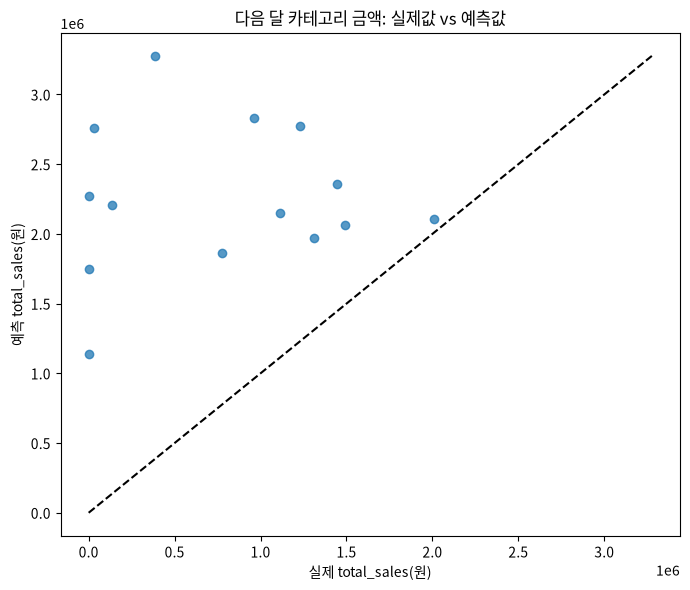

In [21]:
REPORT_DIR.mkdir(parents=True, exist_ok=True)
(REPORT_DIR / "figures").mkdir(parents=True, exist_ok=True)

future_audit.to_csv(REPORT_DIR / "ch09_future_feature_audit.csv", index=False, encoding="utf-8-sig")
future_split_summary.to_csv(REPORT_DIR / "ch09_future_split_summary.csv", index=False, encoding="utf-8-sig")
future_cv_summary.to_csv(REPORT_DIR / "ch09_future_cv_summary.csv", index=False, encoding="utf-8-sig")
future_comparison.to_csv(REPORT_DIR / "ch09_future_model_comparison.csv", index=False, encoding="utf-8-sig")
future_prediction_result.to_csv(REPORT_DIR / "ch09_future_predictions.csv", index=False, encoding="utf-8-sig")
future_validation.drop(columns="passed").to_csv(
    REPORT_DIR / "ch09_future_validation.csv", index=False, encoding="utf-8-sig"
)

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(
    future_prediction_result["total_sales"],
    future_prediction_result["predicted_total_sales"],
    alpha=0.75,
)
low = min(
    future_prediction_result["total_sales"].min(),
    future_prediction_result["predicted_total_sales"].min(),
)
high = max(
    future_prediction_result["total_sales"].max(),
    future_prediction_result["predicted_total_sales"].max(),
)
ax.plot([low, high], [low, high], linestyle="--", color="black")
ax.set_title("다음 달 카테고리 금액: 실제값 vs 예측값")
ax.set_xlabel("실제 total_sales(원)")
ax.set_ylabel("예측 total_sales(원)")
fig.tight_layout()
figure_paths = [
    REPORT_DIR / "figures" / "ch09_future_actual_vs_predicted.png",
    IMAGE_DIR / "final_prediction_result.png",
]
for path in figure_paths:
    fig.savefig(path, dpi=160, bbox_inches="tight")
plt.show()

## 8. 확장 과제 결과

![다음 달 카테고리 금액 예측](images/final_prediction_result.png)

### Target·Feature 설계·Leakage Audit

- 2025-09~2026-06의 70개 `category × month` 표본을 구성했습니다.
- 최종 두 달(2026-05~2026-06, 14행)을 Final Test로 보호했습니다.
- 모든 Feature는 직전 달 또는 그 이전에 확정된 값입니다.
- 예측 대상 월의 `total_sales`, 수량, 주문 수는 입력에서 제외했습니다.

### Train CV·Final Test

| 모델 | Train CV MAE 평균 | 표준편차 | CV R² 평균 |
| --- | ---: | ---: | ---: |
| Random Forest | 877,361 | 110,388 | -0.559 |
| Linear Regression | 1,849,535 | 1,305,615 | -3.171 |

Train 월별 CV로 **Random Forest**를 고정한 후 Final Test를 확인했습니다.

| 모델 | Final MAE | Final RMSE | Final R² | Baseline 대비 MAE 개선율 |
| --- | ---: | ---: | ---: | ---: |
| Last Month Baseline | 1,051,929 | 1,296,306 | -2.895 | 0.00% |
| Random Forest | 1,474,059 | 1,676,871 | -5.517 | -40.13% |

### 결과 관찰·해석

Frozen Model은 직전 달 값을 그대로 사용한 Baseline보다 MAE가 40.13% 더 큽니다. 2026-06 스포츠(실제 386,000원, 예측 약 3,276,726원)와 뷰티(실제 32,000원, 예측 약 2,759,817원)에서 큰 과대예측이 나타났습니다.

### 업무적 사용 판단

**현재 데이터로는 사용 보류**입니다. 문제 정의와 시간 분할은 업무적으로 의미가 있지만, 학습 기간이 8개월에 불과하고 마지막 기간의 변동을 잡지 못했습니다. 적어도 2~3년의 완전한 월별 데이터와 프로모션·재고·휴일·가격 정보를 확보한 뒤 새로운 미래 기간으로 재평가해야 합니다.

## 9. LLM 활용 기록

- **사용 목적:** Prediction Contract·Leakage 후보·시간 분할·Pipeline·평가 문장 검토
- **Prompt 요약:** “다음 달 카테고리 금액 예측에서 미래 정보를 배제하고, 시간 순서 검증과 Baseline 비교를 유지하는지 검토해 달라.”
- **LLM 제안:** lag feature, 월 단위 expanding-window CV, 직전 달 Baseline, 음수 R² 그대로 보고
- **수정한 부분:** 양끝의 부분 월을 제외하고 Final Test를 모델 선택에 사용하지 않았습니다.
- **수정 이유:** 불완전한 기간과 미래 정보 누수로 성능이 과대평가되는 것을 막기 위해서입니다.
- **사람의 검증:** 원본 CSV에서 직접 재집계하고, 월 분할·Feature Audit·Baseline 비교·MAE/RMSE/R²·Validation을 코드로 재확인했습니다.

In [22]:
import subprocess

script_results = []
for script_name in ["prepare_ch09_data.py", "run_regression_analysis.py"]:
    completed = subprocess.run(
        [sys.executable, str(PROJECT_ROOT / "scripts" / script_name)],
        cwd=PROJECT_ROOT,
        text=True,
        capture_output=True,
        check=False,
    )
    script_results.append(
        {
            "script": script_name,
            "returncode": completed.returncode,
            "status": "PASS" if completed.returncode == 0 else "FAIL",
        }
    )
    if completed.returncode != 0:
        print(completed.stdout)
        print(completed.stderr)

script_validation = pd.DataFrame(script_results)
display(script_validation)
assert script_validation["status"].eq("PASS").all()
assert selected_model_name == result["selected_model_name"] == "Random Forest"
assert validation["status"].eq("PASS").all()
assert future_validation["status"].eq("PASS").all()

required_public_files = [
    IMAGE_DIR / "step02_leakage.png",
    IMAGE_DIR / "step04_split.png",
    IMAGE_DIR / "step06_final_metrics.png",
    IMAGE_DIR / "final_prediction_result.png",
    REPORT_DIR / "ch09_regression_validation.csv",
    REPORT_DIR / "ch09_future_validation.csv",
]
file_checks = pd.DataFrame(
    [
        {
            "file": path.relative_to(PROJECT_ROOT).as_posix(),
            "exists": path.exists(),
            "nonempty": path.exists() and path.stat().st_size > 0,
        }
        for path in required_public_files
    ]
)
display(file_checks)
assert file_checks[["exists", "nonempty"]].all().all()
print("FINAL SUBMISSION GATE: PASS")

,script,returncode,status
0,prepare_ch09_data.py,0,PASS
1,run_regression_analysis.py,0,PASS


,file,exists,nonempty
0,chapter09/images/step02_leakage.png,True,True
1,chapter09/images/step04_split.png,True,True
2,chapter09/images/step06_final_metrics.png,True,True
3,chapter09/images/final_prediction_result.png,True,True
4,reports/ch09_regression_validation.csv,True,True
5,reports/ch09_future_validation.csv,True,True


FINAL SUBMISSION GATE: PASS


## 10. 최종 체크

- [x] STEP 0~15 기본 회귀 실습을 완료했습니다.
- [x] `order_total` 예측 요구사항의 업무적 한계를 설명했습니다.
- [x] 미래 숫자형 Target과 Prediction Contract를 정의했습니다.
- [x] 과거에 확정된 Feature만 사용하고 Leakage Audit을 수행했습니다.
- [x] 시간 순서 Train CV와 Final Test를 분리했습니다.
- [x] Baseline과 Frozen Model의 MAE·RMSE·R²를 비교했습니다.
- [x] 낮은 성능을 숨기지 않고 사용 보류로 판단했습니다.
- [x] Internal 식별자 파일을 GitHub 대상에서 제외했습니다.
- [x] 두 스크립트와 Notebook 전체를 처음부터 재실행했습니다.
- [x] 기본·확장 Validation이 모두 PASS입니다.